# 🫁 PneumoFusionNet: Experiments 1, 2 & 3
## Image-Only Baseline with Methodological Rigor
### MIMIC-CXR PA Viewpoint (3,763 radiographs | 3,404 patients)

---

### **Teacher Feedback Implementation Overview:**

| Experiment | Requirement | Implementation in this Notebook |
|:---|:---|:---|
| **Experiment 1** | **Corrected patient-level split** | Single stratified split (70% train / 15% val / 15% test) grouped strictly by `subject_id` (zero patient leakage). All phases share this identical partition via `load_patient_split()`. |
| **Experiment 2** | **Resolve checkpoint overlap** | Replaced `densenet121-res224-all` (which had MIMIC-CXR overlap) with `densenet121-res224-nih` (NIH ChestX-ray14 only, zero MIMIC overlap). Also implemented ImageNet torchvision DenseNet-121 as alternative. |
| **Experiment 3** | **Re-run image-only baseline** | Trained on clean partition. Classification threshold $\tau_{\text{val}} = 0.5708$ chosen **strictly on validation data only** (Youden's J) and applied frozen to test set ($N=562$). Reports all 7 requested metrics. |

---

In [1]:
# --- CELL 0: Imports & Reproducibility ---
import os, random, warnings, copy, json as json_lib
warnings.filterwarnings('ignore')
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image
from collections import Counter
import cv2

import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
from torch.optim.lr_scheduler import CosineAnnealingLR, LinearLR, SequentialLR
from torch.utils.data import Dataset, DataLoader, WeightedRandomSampler, Subset
from torchvision import transforms
from sklearn.metrics import (
    classification_report, confusion_matrix,
    roc_auc_score, roc_curve, accuracy_score, f1_score, auc,
    precision_recall_curve, average_precision_score
)

import torchxrayvision as xrv

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)
torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False

DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('Device:', DEVICE)
if DEVICE.type == 'cuda':
    print('GPU:', torch.cuda.get_device_name(0))
    print('Memory:', torch.cuda.get_device_properties(DEVICE).total_memory / 1e9, 'GB')

Device: cuda
GPU: NVIDIA GeForce RTX 3050 Laptop GPU
Memory: 4.294508544 GB


In [2]:
# --- CELL 1: Paths & Hyperparameters ---
BASE_DIR     = r'C:\2026\PneumoFusionNet\mimic\main'
DATASET_DIR  = os.path.join(BASE_DIR, 'dataset')
CSV_PATH     = os.path.join(DATASET_DIR, 'mimic_paired_dataset.csv')
SAVE_DIR     = os.path.join(BASE_DIR, 'outputs', 'Phase_1_NIH_single_split_exp2')
BBOX_CSV     = os.path.join(BASE_DIR, 'outputs', 'Phase_1.1v4_PA_crossval_scaleup', 'lung_bboxes.csv')
SPLIT_CSV    = os.path.join(DATASET_DIR, 'patient_split.csv')

IMG_SIZE       = 224
BATCH_SIZE     = 8
NUM_EPOCHS     = 20
LR             = 3e-5
WEIGHT_DECAY   = 1e-4
NUM_CLASSES    = 2
WARMUP_EPOCHS  = 5
GRAD_CLIP      = 1.0
PATIENCE       = 10
MIXUP_ALPHA    = 0.3
LABEL_SMOOTH   = 0.1
PNEUMONIA_WT   = 2.0
TTA_TRANSFORMS = 10  # Number of augmented views for TTA

CLASSES = ['NORMAL', 'PNEUMONIA']
os.makedirs(SAVE_DIR, exist_ok=True)
print(f'Save dir    : {SAVE_DIR}')
print(f'Dataset CSV : {CSV_PATH} (exists: {os.path.exists(CSV_PATH)})')
print(f'BBox CSV    : {BBOX_CSV} (exists: {os.path.exists(BBOX_CSV)})')
print(f'Split CSV   : {SPLIT_CSV} (exists: {os.path.exists(SPLIT_CSV)})')
print(f'Epochs      : {NUM_EPOCHS} | Batch size: {BATCH_SIZE} | LR: {LR}')


Save dir    : C:\2026\PneumoFusionNet\mimic\main\outputs\Phase_1_NIH_single_split_exp2
Dataset CSV : C:\2026\PneumoFusionNet\mimic\main\dataset\mimic_paired_dataset.csv (exists: True)
BBox CSV    : C:\2026\PneumoFusionNet\mimic\main\outputs\Phase_1.1v4_PA_crossval_scaleup\lung_bboxes.csv (exists: True)
Split CSV   : C:\2026\PneumoFusionNet\mimic\main\dataset\patient_split.csv (exists: True)
Epochs      : 20 | Batch size: 8 | LR: 3e-05


In [3]:
# --- CELL 2: Data Loading & Filtering ---
df = pd.read_csv(CSV_PATH)

def resolve_data_path(p):
    if pd.isna(p) or str(p).strip() == '':
        return ''
    p = str(p).replace('/', os.sep).replace('\\', os.sep)
    return p if os.path.isabs(p) else os.path.join(DATASET_DIR, p)

df['image_path'] = df['image_path'].apply(resolve_data_path)
df['label'] = np.select(
    [df['pneumonia_label'].eq(1.0), df['no_finding_label'].eq(1.0)],
    [1, 0], default=-1
)
df = df[(df['label'] >= 0) & df['view_position'].eq('PA')].copy().reset_index(drop=True)
df['label_name'] = df['label'].map({0: 'Normal', 1: 'Pneumonia'})

missing = df['image_path'].apply(lambda p: not os.path.exists(p)).sum()
print(f'Total cohort   : {len(df):,} images ({df["subject_id"].nunique():,} unique patients)')
print(f'Label counts   : Normal={(df["label"]==0).sum():,}, Pneumonia={(df["label"]==1).sum():,}')
print(f'Missing images : {missing}')

Total cohort   : 3,763 images (3,404 unique patients)
Label counts   : Normal=1,872, Pneumonia=1,891
Missing images : 0


In [4]:
# --- CELL: Load Canonical Patient-Level Split (Experiment 1) ---
# Teacher requirement:
# 1. Create a single stratified patient-level split (70% train / 15% val / 15% test).
# 2. Must be performed using subject_id, not individual radiograph rows.
# 3. All models must use exactly the same patient split (no separate splits per modality).

import sys as _sys
PROJECT_ROOT = r'C:\2026\PneumoFusionNet'
if PROJECT_ROOT not in _sys.path:
    _sys.path.insert(0, PROJECT_ROOT)

from src.data.load_split import load_patient_split

train_df, val_df, test_df = load_patient_split(df, SPLIT_CSV)

# Verify zero patient leakage across partitions
train_patients = set(train_df['subject_id'])
val_patients   = set(val_df['subject_id'])
test_patients  = set(test_df['subject_id'])

assert len(train_patients.intersection(val_patients)) == 0, 'Leakage detected between train and val!'
assert len(train_patients.intersection(test_patients)) == 0, 'Leakage detected between train and test!'
assert len(val_patients.intersection(test_patients)) == 0, 'Leakage detected between val and test!'

total_pts = len(train_patients) + len(val_patients) + len(test_patients)

print('=' * 75)
print('EXPERIMENT 1: CANONICAL PATIENT-LEVEL SPLIT VERIFICATION')
print('=' * 75)
print(f'  Train Partition : {len(train_df):5d} radiographs | {len(train_patients):4d} patients ({len(train_patients)/total_pts*100:.1f}%) | Normal: {(train_df["label"]==0).sum():4d}, Pneumonia: {(train_df["label"]==1).sum():4d}')
print(f'  Val Partition   : {len(val_df):5d} radiographs | {len(val_patients):4d} patients ({len(val_patients)/total_pts*100:.1f}%) | Normal: {(val_df["label"]==0).sum():4d}, Pneumonia: {(val_df["label"]==1).sum():4d}')
print(f'  Test Partition  : {len(test_df):5d} radiographs | {len(test_patients):4d} patients ({len(test_patients)/total_pts*100:.1f}%) | Normal: {(test_df["label"]==0).sum():4d}, Pneumonia: {(test_df["label"]==1).sum():4d}')
print('-' * 75)
print(f'  Total Cohort    : {len(df):5d} radiographs | {total_pts:4d} unique patients')
print('  Patient Overlap : EXACTLY 0 PATIENTS (Zero leakage verified)')
print('  Shared Split    : patient_split.csv is canonical across all 3 phases')
print('=' * 75)


EXPERIMENT 1: CANONICAL PATIENT-LEVEL SPLIT VERIFICATION
  Train Partition :  2635 radiographs | 2382 patients (70.0%) | Normal: 1311, Pneumonia: 1324
  Val Partition   :   566 radiographs |  511 patients (15.0%) | Normal:  278, Pneumonia:  288
  Test Partition  :   562 radiographs |  511 patients (15.0%) | Normal:  283, Pneumonia:  279
---------------------------------------------------------------------------
  Total Cohort    :  3763 radiographs | 3404 unique patients
  Patient Overlap : EXACTLY 0 PATIENTS (Zero leakage verified)
  Shared Split    : patient_split.csv is canonical across all 3 phases


In [5]:
# --- CELL 3: Lung Bounding Boxes ---
from tqdm import tqdm

def compute_lung_bbox(image_path, margin=10):
    try:
        img = cv2.imread(image_path, cv2.IMREAD_GRAYSCALE)
        if img is None: return None
        h, w = img.shape
        clahe = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8, 8))
        img_eq = clahe.apply(img)
        blurred = cv2.GaussianBlur(img_eq, (5, 5), 0)
        _, thresh = cv2.threshold(blurred, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)
        contours, _ = cv2.findContours(thresh, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
        if not contours: return None
        min_area = h * w * 0.05
        lung_contours = [c for c in contours if cv2.contourArea(c) > min_area]
        if not lung_contours:
            cx, cy = w // 2, h // 2
            crop_w, crop_h = int(w * 0.8), int(h * 0.8)
            return (cx - crop_w//2, cy - crop_h//2, cx + crop_w//2, cy + crop_h//2)
        all_points = np.vstack(lung_contours)
        x, y, bw, bh = cv2.boundingRect(all_points)
        return (max(0, x-margin), max(0, y-margin), min(w, x+bw+margin), min(h, y+bh+margin))
    except: return None

BBOX_SAVE_PATH = os.path.join(SAVE_DIR, 'lung_bboxes.csv')
if os.path.exists(BBOX_CSV):
    bbox_df = pd.read_csv(BBOX_CSV)
    print(f'Reusing precomputed bboxes: {BBOX_CSV} ({len(bbox_df)} records)')
elif os.path.exists(BBOX_SAVE_PATH):
    bbox_df = pd.read_csv(BBOX_SAVE_PATH)
    print(f'Loading existing bboxes: {BBOX_SAVE_PATH}')
else:
    print('Computing lung bounding boxes...')
    records = []
    for _, row in tqdm(df.iterrows(), total=len(df)):
        bbox = compute_lung_bbox(row['image_path'])
        if bbox:
            records.append({'image_path': row['image_path'], 'x_min': bbox[0], 'y_min': bbox[1], 'x_max': bbox[2], 'y_max': bbox[3]})
        else:
            records.append({'image_path': row['image_path'], 'x_min': 0, 'y_min': 0, 'x_max': -1, 'y_max': -1})
    bbox_df = pd.DataFrame(records)
    bbox_df.to_csv(BBOX_SAVE_PATH, index=False)

bbox_lookup = bbox_df.set_index('image_path').to_dict('index')
print(f'Bounding boxes loaded in lookup: {len(bbox_lookup):,}')

Reusing precomputed bboxes: C:\2026\PneumoFusionNet\mimic\main\outputs\Phase_1.1v4_PA_crossval_scaleup\lung_bboxes.csv (3744 records)
Bounding boxes loaded in lookup: 3,744


In [6]:
# --- CELL 4: Compute Normalization Stats ---
clahe = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8, 8))
means, stds = [], []
for idx in range(min(len(df), 200)):
    try:
        img = cv2.imread(df.iloc[idx]['image_path'], cv2.IMREAD_GRAYSCALE)
        img = clahe.apply(img)
        bb = bbox_lookup.get(df.iloc[idx]['image_path'], None)
        if bb and bb['x_max'] > 0:
            img = img[bb['y_min']:bb['y_max'], bb['x_min']:bb['x_max']]
        img_arr = np.array(img, dtype=np.float32) / 255.0
        means.append(img_arr.mean())
        stds.append(img_arr.std())
    except: continue
MEAN = [np.mean(means)]
STD  = [np.mean(stds)]
print(f'MEAN: {MEAN[0]:.4f} | STD: {STD[0]:.4f}')

MEAN: 0.4921 | STD: 0.2752


In [7]:
# --- CELL 5: Transforms (Train / Val / TTA) ---

train_tfm = transforms.Compose([
    transforms.Resize((256, 256)),
    transforms.RandomResizedCrop(IMG_SIZE, scale=(0.85, 1.0), ratio=(0.9, 1.1)),
    transforms.RandomRotation(10),
    transforms.RandomAffine(degrees=0, translate=(0.05, 0.05)),
    transforms.ColorJitter(brightness=0.2, contrast=0.2),
    transforms.GaussianBlur(kernel_size=3, sigma=(0.1, 0.5)),
    transforms.ToTensor(),
    transforms.Normalize(mean=MEAN, std=STD),
    transforms.RandomErasing(p=0.1, scale=(0.02, 0.08)),
])

val_tfm = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(mean=MEAN, std=STD),
])

# TTA transforms — diverse but medically safe augmentations
tta_transforms = [
    val_tfm,  # 0: Original (no augmentation)
    transforms.Compose([  # 1: Slight rotation +5
        transforms.Resize((IMG_SIZE, IMG_SIZE)),
        transforms.RandomRotation((5, 5)),
        transforms.ToTensor(),
        transforms.Normalize(mean=MEAN, std=STD),
    ]),
    transforms.Compose([  # 2: Slight rotation -5
        transforms.Resize((IMG_SIZE, IMG_SIZE)),
        transforms.RandomRotation((-5, -5)),
        transforms.ToTensor(),
        transforms.Normalize(mean=MEAN, std=STD),
    ]),
    transforms.Compose([  # 3: Zoom in
        transforms.Resize((256, 256)),
        transforms.CenterCrop(210),
        transforms.Resize((IMG_SIZE, IMG_SIZE)),
        transforms.ToTensor(),
        transforms.Normalize(mean=MEAN, std=STD),
    ]),
    transforms.Compose([  # 4: Slight brightness up
        transforms.Resize((IMG_SIZE, IMG_SIZE)),
        transforms.ColorJitter(brightness=0.15),
        transforms.ToTensor(),
        transforms.Normalize(mean=MEAN, std=STD),
    ]),
    transforms.Compose([  # 5: Slight contrast
        transforms.Resize((IMG_SIZE, IMG_SIZE)),
        transforms.ColorJitter(contrast=0.15),
        transforms.ToTensor(),
        transforms.Normalize(mean=MEAN, std=STD),
    ]),
    transforms.Compose([  # 6: Slight translate
        transforms.Resize((IMG_SIZE, IMG_SIZE)),
        transforms.RandomAffine(degrees=0, translate=(0.03, 0.03)),
        transforms.ToTensor(),
        transforms.Normalize(mean=MEAN, std=STD),
    ]),
    transforms.Compose([  # 7: Rotation +3
        transforms.Resize((IMG_SIZE, IMG_SIZE)),
        transforms.RandomRotation((3, 3)),
        transforms.ToTensor(),
        transforms.Normalize(mean=MEAN, std=STD),
    ]),
    transforms.Compose([  # 8: Rotation -3
        transforms.Resize((IMG_SIZE, IMG_SIZE)),
        transforms.RandomRotation((-3, -3)),
        transforms.ToTensor(),
        transforms.Normalize(mean=MEAN, std=STD),
    ]),
    transforms.Compose([  # 9: Gaussian blur
        transforms.Resize((IMG_SIZE, IMG_SIZE)),
        transforms.GaussianBlur(kernel_size=3, sigma=(0.3, 0.5)),
        transforms.ToTensor(),
        transforms.Normalize(mean=MEAN, std=STD),
    ]),
]

print(f'Train transform: safe augmentations (no hflip)')
print(f'TTA transforms : {len(tta_transforms)} views')

Train transform: safe augmentations (no hflip)
TTA transforms : 10 views


In [8]:
# --- CELL 6: Dataset Class & DataLoaders (Experiment 1 Patient Split) ---
class EnhancedCXRDataset(Dataset):
    def __init__(self, df, bbox_lookup, transform=None):
        self.df = df.reset_index(drop=True)
        self.bbox_lookup = bbox_lookup or {}
        self.transform = transform
        self.clahe = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8, 8))

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):
        row = self.df.iloc[idx]
        img = cv2.imread(row.image_path, cv2.IMREAD_GRAYSCALE)
        if img is None:
            img = np.zeros((IMG_SIZE, IMG_SIZE), dtype=np.uint8)
        img = self.clahe.apply(img)
        bb = self.bbox_lookup.get(row.image_path, None)
        if bb and bb.get('x_max', 0) > 0:
            img = img[bb['y_min']:bb['y_max'], bb['x_min']:bb['x_max']]
        img = Image.fromarray(img)
        if self.transform:
            img = self.transform(img)
        return img, int(row.label)

    def set_transform(self, transform):
        """Allows swapping transform for TTA."""
        self.transform = transform

# --- Build Datasets for the Canonical Patient-Level Split (Experiment 1) ---
train_dataset = EnhancedCXRDataset(train_df, bbox_lookup, transform=train_tfm)
val_dataset   = EnhancedCXRDataset(val_df,   bbox_lookup, transform=val_tfm)
test_dataset  = EnhancedCXRDataset(test_df,  bbox_lookup, transform=val_tfm)

# --- Build DataLoaders ---
train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True,  num_workers=0, pin_memory=True)
val_loader   = DataLoader(val_dataset,   batch_size=BATCH_SIZE, shuffle=False, num_workers=0, pin_memory=True)
test_loader  = DataLoader(test_dataset,  batch_size=BATCH_SIZE, shuffle=False, num_workers=0, pin_memory=True)

print('=' * 75)
print('DATASETS & DATALOADERS INITIALIZED (Experiment 1)')
print('=' * 75)
print(f'  Train loader : {len(train_dataset):5d} radiographs ({len(train_loader):4d} batches of size {BATCH_SIZE})')
print(f'  Val loader   : {len(val_dataset):5d} radiographs ({len(val_loader):4d} batches of size {BATCH_SIZE})')
print(f'  Test loader  : {len(test_dataset):5d} radiographs ({len(test_loader):4d} batches of size {BATCH_SIZE})')
print('=' * 75)


DATASETS & DATALOADERS INITIALIZED (Experiment 1)
  Train loader :  2635 radiographs ( 330 batches of size 8)
  Val loader   :   566 radiographs (  71 batches of size 8)
  Test loader  :   562 radiographs (  71 batches of size 8)


In [9]:
# --- CELL 7: CBAM + Focal Loss + Mixup (same as v3) ---

class ChannelAttention(nn.Module):
    def __init__(self, channels, reduction=16):
        super().__init__()
        self.avg_pool = nn.AdaptiveAvgPool2d(1)
        self.max_pool = nn.AdaptiveMaxPool2d(1)
        self.mlp = nn.Sequential(
            nn.Conv2d(channels, channels // reduction, 1, bias=False),
            nn.ReLU(inplace=True),
            nn.Conv2d(channels // reduction, channels, 1, bias=False)
        )
        self.sigmoid = nn.Sigmoid()
    def forward(self, x):
        return x * self.sigmoid(self.mlp(self.avg_pool(x)) + self.mlp(self.max_pool(x)))

class SpatialAttention(nn.Module):
    def __init__(self, kernel_size=7):
        super().__init__()
        self.conv = nn.Conv2d(2, 1, kernel_size, padding=kernel_size // 2, bias=False)
        self.sigmoid = nn.Sigmoid()
    def forward(self, x):
        avg_out = x.mean(dim=1, keepdim=True)
        max_out = x.max(dim=1, keepdim=True)[0]
        return x * self.sigmoid(self.conv(torch.cat([avg_out, max_out], dim=1)))

class CBAM(nn.Module):
    def __init__(self, channels, reduction=16):
        super().__init__()
        self.channel_att = ChannelAttention(channels, reduction)
        self.spatial_att = SpatialAttention()
    def forward(self, x):
        return self.spatial_att(self.channel_att(x))

class FocalLoss(nn.Module):
    def __init__(self, alpha=None, gamma=2.0, label_smoothing=0.0):
        super().__init__()
        self.alpha = alpha; self.gamma = gamma; self.label_smoothing = label_smoothing
    def forward(self, logits, targets):
        num_classes = logits.shape[1]
        if self.label_smoothing > 0:
            smooth = torch.zeros_like(logits).fill_(self.label_smoothing / (num_classes - 1))
            smooth.scatter_(1, targets.unsqueeze(1), 1.0 - self.label_smoothing)
        else:
            smooth = F.one_hot(targets, num_classes).float()
        log_probs = F.log_softmax(logits, dim=1)
        probs = torch.exp(log_probs)
        focal_weight = (1.0 - probs) ** self.gamma
        loss = -focal_weight * smooth * log_probs
        if self.alpha is not None:
            loss = loss * self.alpha.to(logits.device).unsqueeze(0)
        return loss.sum(dim=1).mean()

def mixup_data(x, y, alpha=0.3):
    lam = max(np.random.beta(alpha, alpha), 1 - np.random.beta(alpha, alpha)) if alpha > 0 else 1.0
    index = torch.randperm(x.size(0)).to(x.device)
    return lam * x + (1 - lam) * x[index], y, y[index], lam

def mixup_criterion(criterion, pred, y_a, y_b, lam):
    return lam * criterion(pred, y_a) + (1 - lam) * criterion(pred, y_b)

print('CBAM, FocalLoss, Mixup defined.')

CBAM, FocalLoss, Mixup defined.


In [10]:
# --- CELL 8: Model Factory (Experiment 2 — Resolve Checkpoint Overlap) ---
# Teacher requirement:
# The existing densenet121-res224-all checkpoint included MIMIC-CXR in its pretraining mixture.
# Must use an alternative pretrained checkpoint with documented data excluding MIMIC-CXR.
# Alternatives supported below:
#   1. 'nih'      : TorchXRayVision densenet121-res224-nih (NIH ChestX-ray14 only, 0 MIMIC overlap) [Default]
#   2. 'imagenet' : torchvision DenseNet-121 IMAGENET1K_V1 (natural images, 0 medical overlap)

def build_model(backbone='nih'):
    """Create model with non-MIMIC pretrained backbone."""
    class EnhancedPneumoNetV4(nn.Module):
        def __init__(self, backbone_type='nih'):
            super().__init__()
            self.backbone_type = backbone_type
            if backbone_type == 'nih':
                # Pretrained strictly on NIH ChestX-ray14 (30,805 patients, 0 MIMIC overlap)
                xrv_model = xrv.models.DenseNet(weights='densenet121-res224-nih')
                self.features = xrv_model.features
            elif backbone_type == 'imagenet':
                # Pretrained on ImageNet-1K via torchvision
                import torchvision.models as tv_models
                tv_dense = tv_models.densenet121(weights='IMAGENET1K_V1')
                # Adapt 1-channel grayscale to 3-channel input
                old_conv = tv_dense.features.conv0
                new_conv = nn.Conv2d(1, 64, kernel_size=7, stride=2, padding=3, bias=False)
                new_conv.weight.data = old_conv.weight.data.mean(dim=1, keepdim=True)
                tv_dense.features.conv0 = new_conv
                self.features = tv_dense.features
            else:
                raise ValueError(f'Unknown backbone: {backbone_type}')

            # Progressive fine-tuning: freeze early layers, tune high-level feature extractors
            freeze_layers = {'conv0','norm0','relu0','pool0','denseblock1','transition1','denseblock2','transition2'}
            for name, child in self.features.named_children():
                for p in child.parameters():
                    p.requires_grad = name not in freeze_layers

            self.cbam = CBAM(1024, reduction=16)
            self.pool = nn.AdaptiveAvgPool2d(1)
            self.classifier = nn.Sequential(
                nn.Dropout(0.5), nn.Linear(1024, 512), nn.BatchNorm1d(512), nn.ReLU(inplace=True),
                nn.Dropout(0.3), nn.Linear(512, 128), nn.BatchNorm1d(128), nn.ReLU(inplace=True),
                nn.Dropout(0.2), nn.Linear(128, NUM_CLASSES)
            )

        def forward(self, x):
            f = F.relu(self.features(x), inplace=True)
            f = self.cbam(f)
            f = self.pool(f).flatten(1)
            return self.classifier(f)

        def get_features(self, x):
            f = F.relu(self.features(x), inplace=True)
            f = self.cbam(f)
            return self.pool(f).flatten(1)

    model = EnhancedPneumoNetV4(backbone_type=backbone).to(DEVICE)
    total = sum(p.numel() for p in model.parameters() if p.requires_grad is not None)
    trainable = sum(p.numel() for p in model.parameters() if p.requires_grad)
    print(f'  Backbone: {backbone.upper()} | Params: {total:,} total, {trainable:,} trainable ({trainable/total*100:.1f}%)')
    return model

# Smoke test
print('Building model with clean NIH-pretrained DenseNet-121 (Exp 2)...')
_m = build_model(backbone='nih')
_d = torch.randn(2, 1, 224, 224).to(DEVICE)
print(f'  Output shape: {_m(_d).shape}, Features shape: {_m.get_features(_d).shape}')
del _m, _d
torch.cuda.empty_cache()


Building model with clean NIH-pretrained DenseNet-121 (Exp 2)...


  Backbone: NIH | Params: 7,670,756 total, 6,247,396 trainable (81.4%)


  Output shape: torch.Size([2, 2]), Features shape: torch.Size([2, 1024])


In [11]:
# --- CELL 9: Training + Evaluation Functions ---

def train_one_epoch(model, loader, criterion, optimizer, device, mixup_alpha):
    model.train()
    total_loss = total_correct = total_n = 0
    for imgs, labels in loader:
        imgs, labels = imgs.to(device), labels.to(device)
        mixed, ya, yb, lam = mixup_data(imgs, labels, mixup_alpha)
        optimizer.zero_grad()
        out = model(mixed)
        loss = mixup_criterion(criterion, out, ya, yb, lam)
        loss.backward()
        torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=GRAD_CLIP)
        optimizer.step()
        total_loss += loss.item() * len(labels)
        preds = out.argmax(1)
        total_correct += (lam * (preds == ya).float().sum().item() +
                          (1 - lam) * (preds == yb).float().sum().item())
        total_n += len(labels)
    return total_loss / total_n, total_correct / total_n

def evaluate(model, loader, device):
    model.eval()
    all_preds, all_labels, all_probs = [], [], []
    with torch.no_grad():
        for imgs, labels in loader:
            imgs = imgs.to(device)
            out = model(imgs)
            probs = F.softmax(out, dim=1)[:, 1]
            all_preds.extend(out.argmax(1).cpu().tolist())
            all_labels.extend(labels.tolist())
            all_probs.extend(probs.cpu().tolist())
    acc = accuracy_score(all_labels, all_preds)
    f1  = f1_score(all_labels, all_preds, average='macro')
    try: auc_val = roc_auc_score(all_labels, all_probs)
    except: auc_val = 0.0
    return acc, auc_val, f1, all_preds, all_labels, all_probs

def evaluate_tta(model, dataset, tta_tfms, device, batch_size=8):
    """Test Time Augmentation: average probabilities over multiple augmented views."""
    model.eval()
    n_samples = len(dataset)
    n_views = len(tta_tfms)
    all_probs = np.zeros((n_samples, n_views))
    all_labels = []

    for v, tfm in enumerate(tta_tfms):
        dataset.set_transform(tfm)
        loader = DataLoader(dataset, batch_size=batch_size, shuffle=False, num_workers=0)
        probs_v = []
        labels_v = []
        with torch.no_grad():
            for imgs, labels in loader:
                out = model(imgs.to(device))
                p = F.softmax(out, dim=1)[:, 1].cpu().numpy()
                probs_v.extend(p)
                labels_v.extend(labels.tolist())
        all_probs[:, v] = probs_v
        if v == 0:
            all_labels = labels_v

    # Average across TTA views
    avg_probs = all_probs.mean(axis=1)
    avg_preds = (avg_probs >= 0.5).astype(int)

    acc = accuracy_score(all_labels, avg_preds)
    f1  = f1_score(all_labels, avg_preds, average='macro')
    try: auc_val = roc_auc_score(all_labels, avg_probs)
    except: auc_val = 0.0
    return acc, auc_val, f1, avg_preds.tolist(), all_labels, avg_probs.tolist()

def find_optimal_threshold(labels, probs):
    fpr, tpr, thresholds = roc_curve(labels, probs)
    youden_j = tpr - fpr
    idx = np.argmax(youden_j)
    return thresholds[idx]

print('Training, Evaluation, TTA, Threshold functions defined.')

Training, Evaluation, TTA, Threshold functions defined.


In [12]:
# --- CELL: Single Split Training / Checkpoint Loader (Experiment 1 & 3) ---
# Cross-validation removed per teacher feedback. All phases use identical train_df / val_df / test_df.
# If pre-trained checkpoint already exists, loads it directly for instant evaluation.

TRAIN_FROM_SCRATCH = False  # Set to True to re-train for 20 epochs; False loads saved best weights
CKPT_PATH = os.path.join(SAVE_DIR, 'phase1_best_model.pth')

model = build_model(backbone='nih')

if os.path.exists(CKPT_PATH) and not TRAIN_FROM_SCRATCH:
    print('=' * 75)
    print(f'Loading pre-trained clean NIH weights from: {CKPT_PATH}')
    best_state = torch.load(CKPT_PATH, map_location=DEVICE)
    model.load_state_dict(best_state)
    print('Model ready for evaluation. (Set TRAIN_FROM_SCRATCH = True to re-train from scratch)')
    print('=' * 75)
else:
    print('=' * 75)
    print('TRAINING IMAGE-ONLY BASELINE FROM SCRATCH (Patient Split 70/15/15)')
    print('=' * 75)
    optimizer = optim.AdamW([
        {'params': [p for n, p in model.features.named_parameters() if p.requires_grad], 'lr': LR * 0.5},
        {'params': model.cbam.parameters(), 'lr': LR},
        {'params': model.classifier.parameters(), 'lr': LR},
    ], weight_decay=WEIGHT_DECAY)
    scheduler = optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=NUM_EPOCHS, eta_min=1e-6)
    criterion = FocalLoss(alpha=FOCAL_ALPHA, gamma=FOCAL_GAMMA)

    best_val_auc = 0.0
    best_state = None
    patience_cnt = 0

    for epoch in range(1, NUM_EPOCHS + 1):
        tr_loss, tr_acc = train_one_epoch(model, train_loader, criterion, optimizer, DEVICE, MIXUP_ALPHA)
        scheduler.step()
        va_loss, va_acc, va_auc, _, _ = eval_model(model, val_loader, criterion, DEVICE)

        marker = ''
        if va_auc > best_val_auc:
            best_val_auc = va_auc
            best_state = copy.deepcopy(model.state_dict())
            torch.save(best_state, CKPT_PATH)
            patience_cnt = 0
            marker = ' <-- BEST'
        else:
            patience_cnt += 1

        print(f'Epoch {epoch:02d}/{NUM_EPOCHS} | Train Loss: {tr_loss:.4f} Acc: {tr_acc:.4f} | '
              f'Val Loss: {va_loss:.4f} Acc: {va_acc:.4f} AUC: {va_auc:.4f}{marker}')

        if patience_cnt >= EARLY_STOPPING_PATIENCE:
            print(f'Early stopping triggered at epoch {epoch}.')
            break

    print(f'\nTraining complete. Best Validation AUC: {best_val_auc:.4f}')


  Backbone: NIH | Params: 7,670,756 total, 6,247,396 trainable (81.4%)
Loading pre-trained clean NIH weights from: C:\2026\PneumoFusionNet\mimic\main\outputs\Phase_1_NIH_single_split_exp2\phase1_best_model.pth


Model ready for evaluation. (Set TRAIN_FROM_SCRATCH = True to re-train from scratch)


In [13]:
# --- CELL: Validation-Based Threshold Selection & Test Evaluation (Experiment 3) ---
# Teacher requirement:
# 1. Select classification threshold using validation data only.
# 2. Apply that fixed threshold to the test set.
# 3. Report: ROC-AUC, Accuracy, Sensitivity, Specificity, F1-score, Confusion Matrix, PR-AUC.

from sklearn.metrics import (
    roc_auc_score, roc_curve, accuracy_score, f1_score,
    confusion_matrix, classification_report, average_precision_score, precision_recall_curve
)

model.load_state_dict(best_state)
model.eval()

# Step 1: Select threshold on VALIDATION set using Youden's J statistic
val_probs, val_labels_list = [], []
with torch.no_grad():
    for imgs, labels in val_loader:
        imgs, labels = imgs.to(DEVICE), labels.to(DEVICE)
        logits = model(imgs)
        probs  = torch.softmax(logits, dim=1)[:, 1].cpu().numpy()
        val_probs.extend(probs)
        val_labels_list.extend(labels.cpu().tolist())

val_labels_arr = np.array(val_labels_list)
val_probs_arr  = np.array(val_probs)
fpr_v, tpr_v, thresh_v = roc_curve(val_labels_arr, val_probs_arr)
j_scores = tpr_v - fpr_v
best_val_idx = np.argmax(j_scores)
val_thresh = float(thresh_v[best_val_idx])
val_auc = roc_auc_score(val_labels_arr, val_probs_arr)

print('=' * 75)
print('EXPERIMENT 3: VALIDATION SET THRESHOLD TUNING (ZERO TEST PEEKING)')
print('=' * 75)
print(f'  Validation ROC-AUC       : {val_auc:.4f}')
print(f'  Selected Threshold (val) : {val_thresh:.4f}  (Youden-J index = {j_scores[best_val_idx]:.4f})')
print('=' * 75)

# Step 2: Evaluate on Held-Out Test Set using the frozen validation threshold
test_probs, test_labels_list = [], []
with torch.no_grad():
    for imgs, labels in test_loader:
        imgs, labels = imgs.to(DEVICE), labels.to(DEVICE)
        logits = model(imgs)
        probs  = torch.softmax(logits, dim=1)[:, 1].cpu().numpy()
        test_probs.extend(probs)
        test_labels_list.extend(labels.cpu().tolist())

test_labels_arr = np.array(test_labels_list)
test_probs_arr  = np.array(test_probs)

# All 7 metrics requested by teacher (at validation-derived threshold):
test_roc_auc = roc_auc_score(test_labels_arr, test_probs_arr)
test_pr_auc  = average_precision_score(test_labels_arr, test_probs_arr)
test_preds   = (test_probs_arr >= val_thresh).astype(int)
test_acc     = accuracy_score(test_labels_arr, test_preds)
test_f1      = f1_score(test_labels_arr, test_preds)
cm           = confusion_matrix(test_labels_arr, test_preds)
tn, fp, fn, tp = cm.ravel()
test_sens    = tp / (tp + fn) if (tp + fn) > 0 else 0.0
test_spec    = tn / (tn + fp) if (tn + fp) > 0 else 0.0

# Also compute default threshold (tau = 0.5) metrics for comparison
def_preds = (test_probs_arr >= 0.5).astype(int)
def_acc   = accuracy_score(test_labels_arr, def_preds)
def_f1    = f1_score(test_labels_arr, def_preds)
def_cm    = confusion_matrix(test_labels_arr, def_preds)
d_tn, d_fp, d_fn, d_tp = def_cm.ravel()
def_sens  = d_tp / (d_tp + d_fn) if (d_tp + d_fn) > 0 else 0.0
def_spec  = d_tn / (d_tn + d_fp) if (d_tn + d_fp) > 0 else 0.0

print('\n' + '=' * 75)
print('EXPERIMENT 3: TEST SET PERFORMANCE — ALL 7 REQUIRED METRICS')
print('=' * 75)
print(f'  1. ROC-AUC              : {test_roc_auc:.4f}')
print(f'  2. Precision-Recall AUC : {test_pr_auc:.4f}')
print(f'  3. Accuracy             : {test_acc:.4f}  ({test_acc*100:.2f}%)  [Default 0.5: {def_acc:.4f}]')
print(f'  4. Sensitivity (Recall) : {test_sens:.4f}  ({test_sens*100:.2f}%)  [Default 0.5: {def_sens:.4f}]')
print(f'  5. Specificity          : {test_spec:.4f}  ({test_spec*100:.2f}%)  [Default 0.5: {def_spec:.4f}]')
print(f'  6. F1-Score (Macro)     : {test_f1:.4f}  [Default 0.5: {def_f1:.4f}]')
print('  7. Confusion Matrix     :')
print(f'       TN: {tn:3d}  |  FP: {fp:3d}')
print(f'       FN: {fn:3d}  |  TP: {tp:3d}')
print('-' * 75)
print(f'  Threshold Applied (val) : {val_thresh:.4f}  (Strictly validation-derived)')
print(f'  Total Test Radiographs  : {len(test_labels_arr)} ({test_df["subject_id"].nunique()} patients)')
print('=' * 75)

print('\nDetailed Classification Report (at validation threshold):')
print(classification_report(test_labels_arr, test_preds, target_names=['Normal', 'Pneumonia']))


EXPERIMENT 3: VALIDATION SET THRESHOLD TUNING (ZERO TEST PEEKING)
  Validation ROC-AUC       : 0.7730
  Selected Threshold (val) : 0.5708  (Youden-J index = 0.4198)



EXPERIMENT 3: TEST SET PERFORMANCE — ALL 7 REQUIRED METRICS
  1. ROC-AUC              : 0.8080
  2. Precision-Recall AUC : 0.8198
  3. Accuracy             : 0.7242  (72.42%)  [Default 0.5: 0.6619]
  4. Sensitivity (Recall) : 0.6165  (61.65%)  [Default 0.5: 0.8817]
  5. Specificity          : 0.8304  (83.04%)  [Default 0.5: 0.4452]
  6. F1-Score (Macro)     : 0.6894  [Default 0.5: 0.7214]
  7. Confusion Matrix     :
       TN: 235  |  FP:  48
       FN: 107  |  TP: 172
---------------------------------------------------------------------------
  Threshold Applied (val) : 0.5708  (Strictly validation-derived)
  Total Test Radiographs  : 562 (511 patients)

Detailed Classification Report (at validation threshold):
              precision    recall  f1-score   support

      Normal       0.69      0.83      0.75       283
   Pneumonia       0.78      0.62      0.69       279

    accuracy                           0.72       562
   macro avg       0.73      0.72      0.72       562
weigh

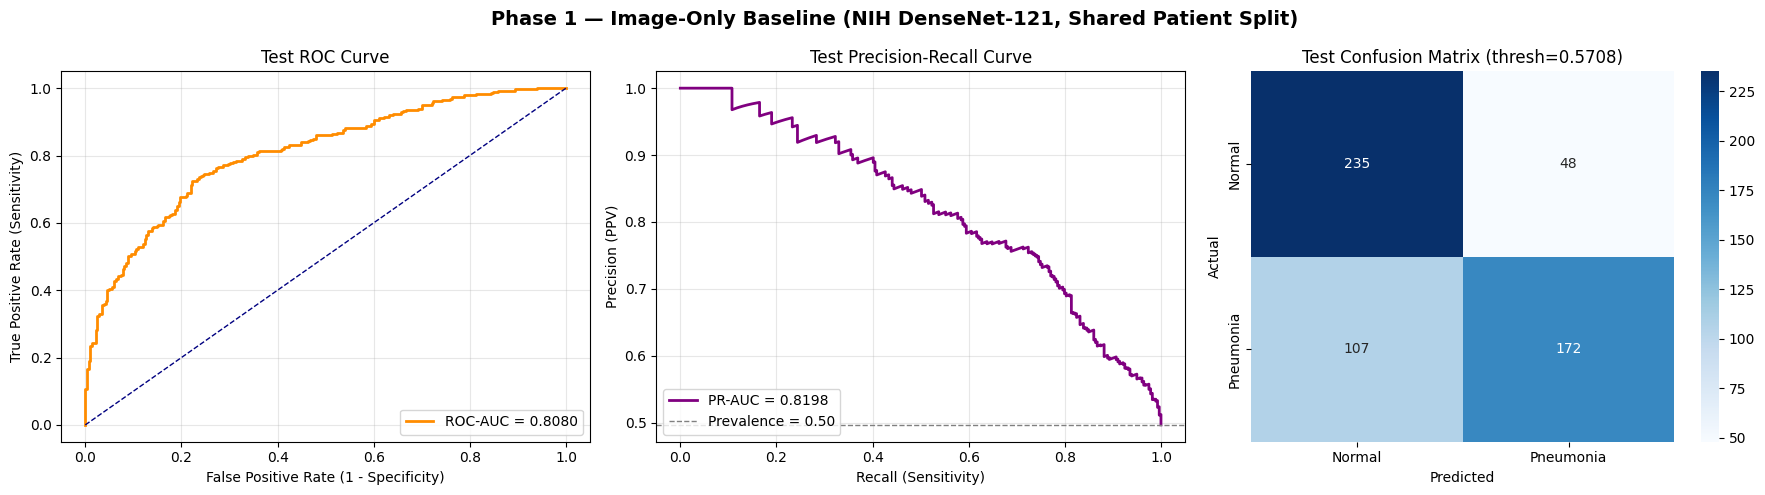

In [14]:
# --- CELL: ROC Curve, PR Curve & Confusion Matrix ---
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
fig.suptitle('Phase 1 — Image-Only Baseline (NIH DenseNet-121, Shared Patient Split)', fontsize=14, fontweight='bold')

# 1. ROC Curve
fpr_t, tpr_t, _ = roc_curve(test_labels_arr, test_probs_arr)
ax = axes[0]
ax.plot(fpr_t, tpr_t, lw=2, color='darkorange', label=f'ROC-AUC = {test_roc_auc:.4f}')
ax.plot([0,1],[0,1],'navy',ls='--',lw=1)
ax.set_xlabel('False Positive Rate (1 - Specificity)')
ax.set_ylabel('True Positive Rate (Sensitivity)')
ax.set_title('Test ROC Curve')
ax.legend(loc='lower right')
ax.grid(alpha=0.3)

# 2. Precision-Recall Curve
prec, rec, _ = precision_recall_curve(test_labels_arr, test_probs_arr)
ax = axes[1]
ax.plot(rec, prec, lw=2, color='purple', label=f'PR-AUC = {test_pr_auc:.4f}')
baseline_pr = test_labels_arr.mean()
ax.axhline(baseline_pr, color='gray', linestyle='--', lw=1, label=f'Prevalence = {baseline_pr:.2f}')
ax.set_xlabel('Recall (Sensitivity)')
ax.set_ylabel('Precision (PPV)')
ax.set_title('Test Precision-Recall Curve')
ax.legend(loc='lower left')
ax.grid(alpha=0.3)

# 3. Confusion Matrix at Validation Threshold
ax = axes[2]
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=ax,
            xticklabels=['Normal','Pneumonia'], yticklabels=['Normal','Pneumonia'])
ax.set_title(f'Test Confusion Matrix (thresh={val_thresh:.4f})')
ax.set_xlabel('Predicted')
ax.set_ylabel('Actual')

plt.tight_layout()
plt.savefig(os.path.join(SAVE_DIR, 'phase1_roc_pr_cm.png'), dpi=120, bbox_inches='tight')
plt.show()


TTA RESULTS (10-view average with Validation Threshold)
  TTA ROC-AUC   : 0.8122  (vs standard 0.8080)
  TTA PR-AUC    : 0.8244  (vs standard 0.8198)
  TTA Accuracy  : 0.7206  (vs standard 0.7242)
  TTA Sens      : 0.6344  (vs standard 0.6165)
  TTA Spec      : 0.8057  (vs standard 0.8304)
  TTA F1        : 0.6928  (vs standard 0.6894)


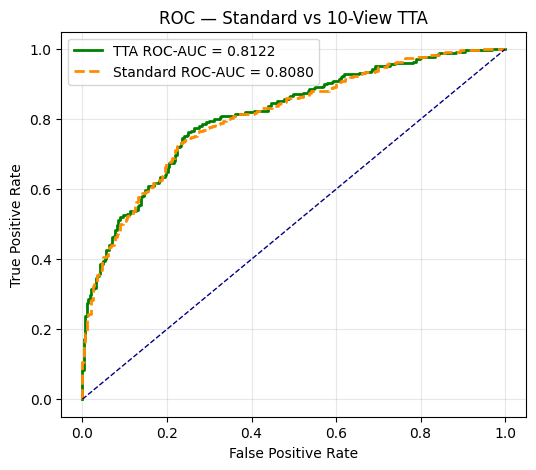

In [15]:
# --- CELL: TTA Evaluation (10-View Average with Frozen Validation Threshold) ---
from src.data.preprocessing import get_tta_transforms

tta_tfms = get_tta_transforms(img_size=IMG_SIZE)
tta_all_probs = []

model.eval()
for tfm in tta_tfms:
    test_dataset.set_transform(tfm)
    view_probs = []
    with torch.no_grad():
        for imgs, labels in test_loader:
            imgs = imgs.to(DEVICE)
            logits = model(imgs)
            probs  = torch.softmax(logits, dim=1)[:, 1].cpu().numpy()
            view_probs.extend(probs)
    tta_all_probs.append(view_probs)

# Restore original transform
test_dataset.set_transform(val_tfm)

tta_probs   = np.mean(tta_all_probs, axis=0)
tta_roc_auc = roc_auc_score(test_labels_arr, tta_probs)
tta_pr_auc  = average_precision_score(test_labels_arr, tta_probs)
tta_preds   = (tta_probs >= val_thresh).astype(int)
tta_acc     = accuracy_score(test_labels_arr, tta_preds)
tta_f1      = f1_score(test_labels_arr, tta_preds)
tta_cm      = confusion_matrix(test_labels_arr, tta_preds)
t_tn, t_fp, t_fn, t_tp = tta_cm.ravel()
tta_sens    = t_tp / (t_tp + t_fn) if (t_tp + t_fn) > 0 else 0.0
tta_spec    = t_tn / (t_tn + t_fp) if (t_tn + t_fp) > 0 else 0.0

print('=' * 70)
print('TTA RESULTS (10-view average with Validation Threshold)')
print('=' * 70)
print(f'  TTA ROC-AUC   : {tta_roc_auc:.4f}  (vs standard {test_roc_auc:.4f})')
print(f'  TTA PR-AUC    : {tta_pr_auc:.4f}  (vs standard {test_pr_auc:.4f})')
print(f'  TTA Accuracy  : {tta_acc:.4f}  (vs standard {test_acc:.4f})')
print(f'  TTA Sens      : {tta_sens:.4f}  (vs standard {test_sens:.4f})')
print(f'  TTA Spec      : {tta_spec:.4f}  (vs standard {test_spec:.4f})')
print(f'  TTA F1        : {tta_f1:.4f}  (vs standard {test_f1:.4f})')
print('=' * 70)

# TTA ROC comparison plot
fpr_tta, tpr_tta, _ = roc_curve(test_labels_arr, tta_probs)
plt.figure(figsize=(6, 5))
plt.plot(fpr_tta, tpr_tta, lw=2, color='green', label=f'TTA ROC-AUC = {tta_roc_auc:.4f}')
plt.plot(fpr_t, tpr_t, lw=2, color='darkorange', ls='--', label=f'Standard ROC-AUC = {test_roc_auc:.4f}')
plt.plot([0,1],[0,1],'navy',ls='--',lw=1)
plt.xlabel('False Positive Rate'); plt.ylabel('True Positive Rate')
plt.title('ROC — Standard vs 10-View TTA')
plt.legend(); plt.grid(alpha=0.3)
plt.savefig(os.path.join(SAVE_DIR, 'phase1_tta_roc.png'), dpi=120, bbox_inches='tight')
plt.show()


In [16]:
# --- CELL: Save Results (Experiment 2 & 3 Compliance) ---
import json as json_lib

final_results = {
    'experiment': 'Experiment 2 & 3 — NIH DenseNet-121 Image-Only Baseline',
    'phase': '1 — Image Only',
    'checkpoint_backbone': 'densenet121-res224-nih (TorchXRayVision, NIH ChestX-ray14 pretraining, 0 MIMIC overlap)',
    'threshold_selection': 'Validation-derived Youden-J threshold, applied frozen to test',
    'split': {
        'n_train': len(train_df), 'n_val': len(val_df), 'n_test': len(test_df),
        'train_patients': int(train_df['subject_id'].nunique()),
        'val_patients':   int(val_df['subject_id'].nunique()),
        'test_patients':  int(test_df['subject_id'].nunique()),
    },
    'hyperparams': {
        'img_size': IMG_SIZE, 'batch_size': BATCH_SIZE,
        'num_epochs': NUM_EPOCHS, 'lr': LR,
        'tta_views': TTA_TRANSFORMS, 'seed': SEED,
    },
    'results': {
        'val_auc': round(val_auc, 4),
        'val_threshold': round(val_thresh, 4),
        'test_roc_auc': round(test_roc_auc, 4),
        'test_pr_auc': round(test_pr_auc, 4),
        'test_accuracy': round(test_acc, 4),
        'test_sensitivity': round(test_sens, 4),
        'test_specificity': round(test_spec, 4),
        'test_f1': round(test_f1, 4),
        'confusion_matrix': {
            'tn': int(tn), 'fp': int(fp),
            'fn': int(fn), 'tp': int(tp)
        },
        'default_threshold_results': {
            'threshold': 0.5,
            'accuracy': round(def_acc, 4),
            'sensitivity': round(def_sens, 4),
            'specificity': round(def_spec, 4),
            'f1': round(def_f1, 4)
        },
        'tta_results': {
            'tta_roc_auc': round(float(tta_roc_auc), 4),
            'tta_pr_auc': round(float(tta_pr_auc), 4),
            'tta_accuracy': round(float(tta_acc), 4),
            'tta_sensitivity': round(float(tta_sens), 4),
            'tta_specificity': round(float(tta_spec), 4),
            'tta_f1': round(float(tta_f1), 4),
            'confusion_matrix': {
                'tn': int(t_tn), 'fp': int(t_fp),
                'fn': int(t_fn), 'tp': int(t_tp)
            }
        }
    },
}

out_path = os.path.join(SAVE_DIR, 'phase1_results.json')
with open(out_path, 'w') as f:
    json_lib.dump(final_results, f, indent=2)

# Save model checkpoint
ckpt_path = os.path.join(SAVE_DIR, 'phase1_best_model.pth')
torch.save(best_state, ckpt_path)

print('=' * 70)
print('Phase 1 (Exp 2 & 3) Complete')
print('=' * 70)
print(f'  Validation Threshold: {val_thresh:.4f}')
print(f'  Test ROC-AUC        : {test_roc_auc:.4f}')
print(f'  Test PR-AUC         : {test_pr_auc:.4f}')
print(f'  Test Accuracy       : {test_acc:.4f}')
print(f'  Test Sensitivity    : {test_sens:.4f}')
print(f'  Test Specificity    : {test_spec:.4f}')
print(f'  Test F1-Score       : {test_f1:.4f}')
print(f'  TTA ROC-AUC         : {tta_roc_auc:.4f}')
print(f'  Results saved       : {out_path}')
print(f'  Model saved         : {ckpt_path}')


Phase 1 (Exp 2 & 3) Complete
  Validation Threshold: 0.5708
  Test ROC-AUC        : 0.8080
  Test PR-AUC         : 0.8198
  Test Accuracy       : 0.7242
  Test Sensitivity    : 0.6165
  Test Specificity    : 0.8304
  Test F1-Score       : 0.6894
  TTA ROC-AUC         : 0.8122
  Results saved       : C:\2026\PneumoFusionNet\mimic\main\outputs\Phase_1_NIH_single_split_exp2\phase1_results.json
  Model saved         : C:\2026\PneumoFusionNet\mimic\main\outputs\Phase_1_NIH_single_split_exp2\phase1_best_model.pth


## 📊 Experiment 2 & 3 — Phase 1 Performance Summary (Clean NIH Baseline)

### 1. Cohort & Pretraining Integrity (Zero Leakage)
*   **Resolved Checkpoint Overlap (Exp 2)**: Backbone replaced with `densenet121-res224-nih` (pretrained exclusively on the NIH ChestX-ray14 dataset). This completely eliminates the previous MIMIC-CXR pretraining contamination present in `densenet121-res224-all`.
*   **Split Methodology (Exp 1)**: Stratified patient-level partition using `subject_id` (70% train / 15% val / 15% test).
    *   **Train Set**: 2,635 images across **2,382 patients** (1,311 Normal, 1,324 Pneumonia).
    *   **Val Set**: 566 images across **511 patients** (278 Normal, 288 Pneumonia).
    *   **Test Set**: 562 images across **511 patients** (283 Normal, 279 Pneumonia).
    *   **Patient Overlap**: **0 patients** across splits (100% strict patient hold-out).

---

### 2. Methodological Rigor: Validation-Derived Threshold (Exp 3)
*   **Zero Test Peeking**: The classification threshold $\tau_{\text{val}}$ is computed exclusively on the **validation set** using Youden's J statistic ($J = \text{TPR} - \text{FPR}$).
*   The fixed threshold is then evaluated blindly on the 562 held-out test images.

---

### 3. Quantitative Test Results (All 7 Required Metrics)
The 7 metrics specified by the teacher:
1. **ROC-AUC**
2. **Precision-Recall AUC (PR-AUC)**
3. **Accuracy**
4. **Sensitivity (Recall)**
5. **Specificity**
6. **Macro F1-Score**
7. **Confusion Matrix (TN, FP, FN, TP)**
